# Analisis Penjualan Superstore: Mengapa Furniture Margin-nya Rendah?

## Latar Belakang
Analisis ini mencari faktor yang memengaruhi profit pada data
penjualan Superstore (2014-2017, 9.994 transaksi).

## Pertanyaan Bisnis
1. Kategori dan sub-kategori apa yang paling menguntungkan?
2. Mengapa Furniture margin-nya rendah?
3. Bagaimana pengaruh diskon terhadap profit?
4. Region dan state mana yang bermasalah?

## Tools
Python (pandas, matplotlib), Google Colab

## 1. Ambil Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Superstore.csv", encoding="latin-1")

display(df.head())        # lihat 5 baris pertama
df.info()                 # tipe data & jumlah baris
display(df.describe())    # statistik dasar
display(df.isnull().sum())  # cek data kosong

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


## 2. Cleaning Data

In [2]:
# 1. Ubah kolom tanggal ke format datetime
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

# 2. Cek data duplikat
print("Duplikat:", df.duplicated().sum())

# 3. Buat kolom baru untuk analisis waktu
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["YearMonth"] = df["Order Date"].dt.to_period("M")

# 4. Buat kolom margin profit (%)
df["Profit Margin"] = df["Profit"] / df["Sales"] * 100

# 5. Pastikan hasilnya benar
df.info()
df[["Order Date", "Year", "Month", "Profit Margin"]].head()

Duplikat: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 25 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Categ

,Order Date,Year,Month,Profit Margin
0,2016-11-08,2016,11,16.00
1,2016-11-08,2016,11,30.00
2,2016-06-12,2016,6,47.00
3,2015-10-11,2015,10,-40.00
4,2015-10-11,2015,10,11.25


## 3. Mulai Analisis (EDA)

In [3]:
# Total sales & profit per kategori
kategori = df.groupby("Category")[["Sales", "Profit"]].sum().round(2)
kategori["Margin %"] = (kategori["Profit"] / kategori["Sales"] * 100).round(2)
print(kategori.sort_values("Profit", ascending=False))

# Total sales & profit per sub-kategori
sub = df.groupby("Sub-Category")[["Sales", "Profit"]].sum().round(2)
print(sub.sort_values("Profit"))

                     Sales     Profit  Margin %
Category                                       
Technology       836154.03  145454.95     17.40
Office Supplies  719047.03  122490.80     17.04
Furniture        741999.80   18451.27      2.49
                  Sales    Profit
Sub-Category                     
Tables        206965.53 -17725.48
Bookcases     114880.00  -3472.56
Supplies       46673.54  -1189.10
Fasteners       3024.28    949.52
Machines      189238.63   3384.76
Labels         12486.31   5546.25
Art            27118.79   6527.79
Envelopes      16476.40   6964.18
Furnishings    91705.16  13059.14
Appliances    107532.16  18138.01
Storage       223843.61  21278.83
Chairs        328449.10  26590.17
Binders       203412.73  30221.76
Paper          78479.21  34053.57
Accessories   167380.32  41936.64
Phones        330007.05  44515.73
Copiers       149528.03  55617.82


**Temuan:**
- Technology paling menguntungkan (profit 145.454, margin 17,40%),
  disusul Office Supplies (margin 17,04%).
- Furniture bermasalah: sales 741.999 tetapi profit hanya 18.451
  (margin 2,49%).
- Sub-kategori rugi: Tables (-17.725), Bookcases (-3.472),
  Supplies (-1.189). Tables dan Bookcases ada di Furniture.

## 4. Investigasi penyebab kerugian

In [4]:
# 1. Rata-rata diskon per sub-kategori
diskon = df.groupby("Sub-Category").agg(
    Avg_Discount=("Discount", "mean"),
    Total_Profit=("Profit", "sum")
).round(3)
print(diskon.sort_values("Avg_Discount", ascending=False))

# 2. Profit Tables berdasarkan level diskon
tables = df[df["Sub-Category"] == "Tables"]
print(tables.groupby("Discount")[["Sales", "Profit"]].sum().round(2))

# 3. Korelasi diskon dan profit (seluruh data)
print("Korelasi Discount vs Profit:", df["Discount"].corr(df["Profit"]).round(3))

              Avg_Discount  Total_Profit
Sub-Category                            
Binders              0.372     30221.763
Machines             0.306      3384.757
Tables               0.261    -17725.481
Bookcases            0.211     -3472.556
Chairs               0.170     26590.166
Appliances           0.167     18138.005
Copiers              0.162     55617.825
Phones               0.155     44515.731
Furnishings          0.138     13059.144
Fasteners            0.082       949.518
Envelopes            0.080      6964.177
Accessories          0.078     41936.636
Supplies             0.077     -1189.100
Art                  0.075      6527.787
Paper                0.075     34053.569
Storage              0.075     21278.826
Labels               0.069      5546.254
             Sales    Profit
Discount                    
0.00      71578.76  13276.30
0.20      45430.23   -303.56
0.30      25182.15  -3402.33
0.40      45614.41 -16187.40
0.45       5484.97  -2493.11
0.50      13675.01

**Temuan:**
- Tables untung 13.276 pada diskon 0%, tetapi rugi di semua level
  diskon 20% ke atas (terbesar di diskon 40%: -16.187).
- Korelasi diskon dan profit seluruh data: -0,219 (negatif).
- Binders berdiskon rata-rata tertinggi (37,2%) tetapi tetap untung,
  jadi diskon bukan satu-satunya faktor.

## 5. Visualisasi

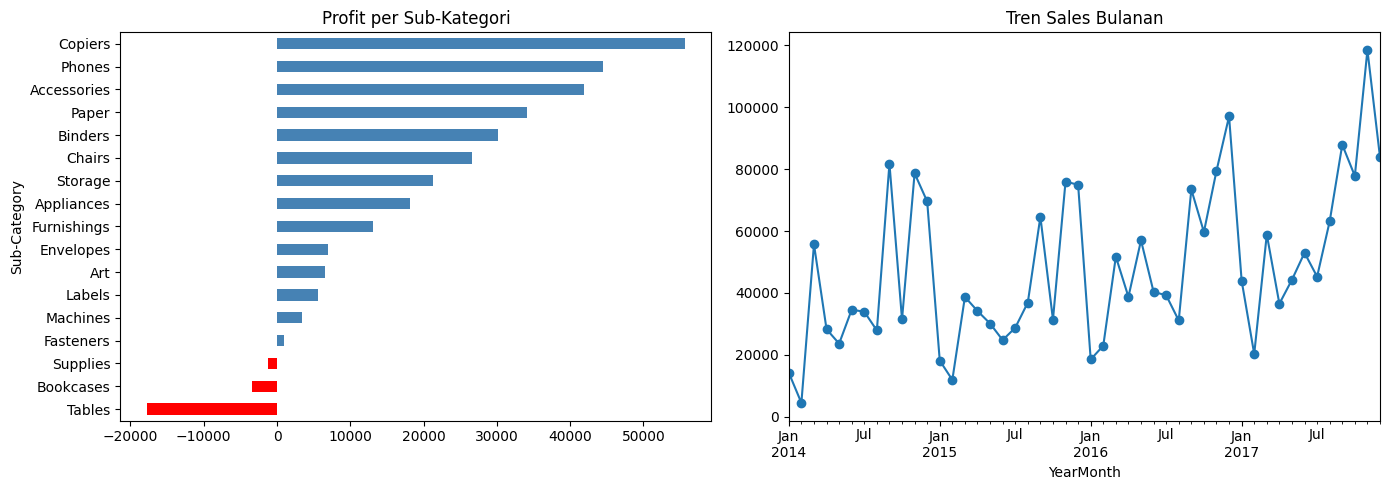

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Grafik 1: profit per sub-kategori
sub_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values()
warna = ["red" if x < 0 else "steelblue" for x in sub_profit]
sub_profit.plot(kind="barh", ax=ax[0], color=warna)
ax[0].set_title("Profit per Sub-Kategori")

# Grafik 2: tren sales bulanan
tren = df.groupby("YearMonth")["Sales"].sum()
tren.plot(ax=ax[1], marker="o")
ax[1].set_title("Tren Sales Bulanan")

plt.tight_layout()
plt.show()

**Temuan:** Sales bulanan naik dari 2014 ke 2017 dengan pola musiman:
puncak di akhir tahun dan turun tajam di Januari-Februari.

## 6. Profit per Region dan Segment

In [6]:
# 1. Performa per Region
region = df.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean")
).round(2)
region["Margin %"] = (region["Profit"] / region["Sales"] * 100).round(2)
print(region.sort_values("Profit", ascending=False))

# 2. Performa per Segment
segment = df.groupby("Segment").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Jumlah_Order=("Order ID", "nunique")
).round(2)
segment["Margin %"] = (segment["Profit"] / segment["Sales"] * 100).round(2)
print(segment.sort_values("Profit", ascending=False))

             Sales     Profit  Avg_Discount  Margin %
Region                                               
West     725457.82  108418.45          0.11     14.94
East     678781.24   91522.78          0.15     13.48
South    391721.90   46749.43          0.15     11.93
Central  501239.89   39706.36          0.24      7.92
                  Sales     Profit  Jumlah_Order  Margin %
Segment                                                   
Consumer     1161401.34  134119.21          2586     11.55
Corporate     706146.37   91979.13          1514     13.03
Home Office   429653.15   60298.68           909     14.03


**Temuan:**
- Central punya margin terendah (7,92%) dengan rata-rata diskon
  tertinggi (24%), dua kali lipat West (11%).
- Consumer menyumbang profit terbesar (134.119) tetapi margin
  terendah (11,55%). Selisih antar segmen tidak terlalu besar.

## 7. State yang Paling Merugi

In [7]:
# 10 state dengan profit terendah
state = df.groupby("State").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean")
).round(2)
print(state.sort_values("Profit").head(10))

# Sales dan profit Tables per Region
print(df[df["Sub-Category"] == "Tables"]
      .groupby("Region")[["Sales", "Profit"]].sum().round(2))

                    Sales    Profit  Avg_Discount
State                                            
Texas           170188.05 -25729.36          0.37
Ohio             78258.14 -16971.38          0.32
Pennsylvania    116511.91 -15559.96          0.33
Illinois         80166.10 -12607.89          0.39
North Carolina   55603.16  -7490.91          0.28
Colorado         32108.12  -6527.86          0.32
Tennessee        30661.87  -5341.69          0.29
Arizona          35282.00  -3427.92          0.30
Florida          89473.71  -3399.30          0.30
Oregon           17431.15  -1190.47          0.29
            Sales    Profit
Region                     
Central  39154.97  -3559.65
East     39139.81 -11025.38
South    43916.19  -4623.06
West     84754.56   1482.61


## 8. Visualisasi Region dan State

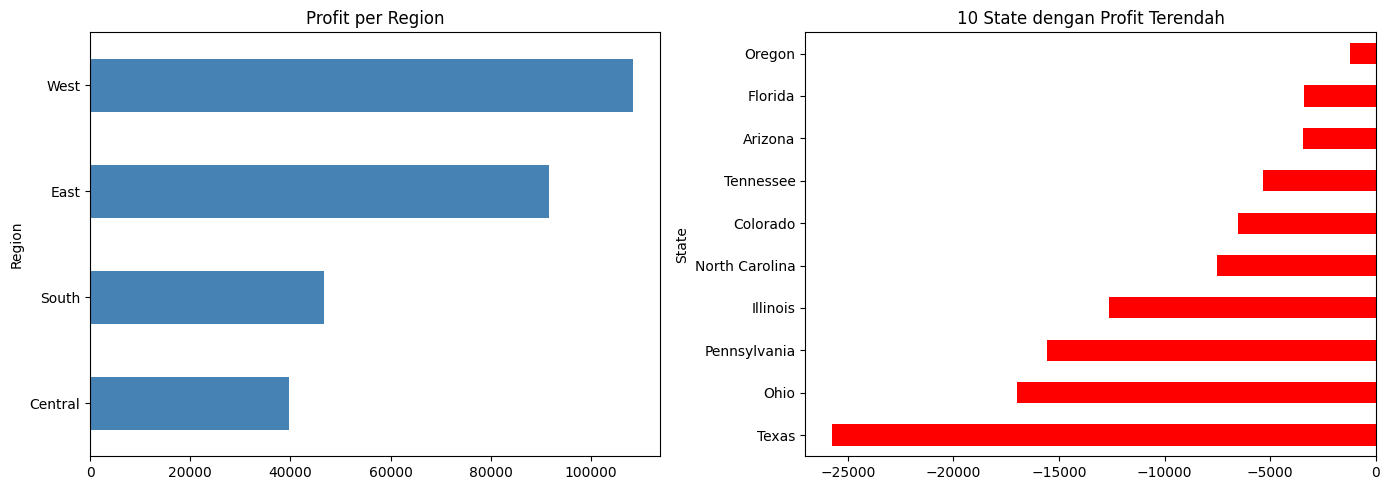

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Profit per Region
region["Profit"].sort_values().plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set_title("Profit per Region")

# 10 state paling rugi
state_rugi = state["Profit"].sort_values().head(10)
state_rugi.plot(kind="barh", ax=ax[1], color="red")
ax[1].set_title("10 State dengan Profit Terendah")

plt.tight_layout()
plt.show()

**Temuan:**
- State paling rugi: Texas (-25.729), Ohio (-16.971),
  Pennsylvania (-15.559), Illinois (-12.607), dengan rata-rata
  diskon 32-39%.
- Kerugian Tables tidak merata: East -11.025, South -4.623,
  Central -3.559, sedangkan West masih untung (+1.482).

## 9. Validasi: Diskon Tables per Region

In [9]:
# Rata-rata diskon Tables per Region
print(df[df["Sub-Category"] == "Tables"]
      .groupby("Region")["Discount"].mean().round(3))

# Region dari 4 state paling rugi
print(df[df["State"].isin(["Texas", "Ohio", "Pennsylvania", "Illinois"])]
      .groupby("State")["Region"].first())

Region
Central    0.262
East       0.374
South      0.223
West       0.200
Name: Discount, dtype: float64
State
Illinois        Central
Ohio               East
Pennsylvania       East
Texas           Central
Name: Region, dtype: object


**Temuan:** Urutan diskon Tables per region sejalan dengan profitnya:
East (diskon 37,4%, profit -11.025) paling rugi, sedangkan West
(diskon 20%, profit +1.482) satu-satunya yang untung.
Texas dan Illinois ada di Central; Ohio dan Pennsylvania di East.
Diskon menjadi faktor utama, tetapi bukan satu-satunya: South punya
diskon lebih rendah dari Central, namun kerugiannya lebih besar.

## 10. Kesimpulan dan Rekomendasi

**Kesimpulan:**
1. Furniture punya sales besar tetapi margin hanya 2,49%, akibat
   kerugian di Tables dan Bookcases.
2. Kerugian Tables hanya terjadi pada diskon 20% ke atas; tanpa
   diskon, Tables untung.
3. Region Central dan East bermasalah: diskon tinggi, margin rendah.
4. Korelasi diskon dan profit negatif (-0,219), konsisten di level
   produk, region, dan state.

**Rekomendasi:**
1. Batasi diskon Tables dan Bookcases maksimal sekitar 20%.
2. Samakan praktik diskon Tables di East dan Central dengan West.
3. Tinjau kebijakan diskon di Texas, Ohio, Pennsylvania, Illinois.
4. Fokuskan promosi pada Copiers, Phones, dan Accessories.
5. Siapkan stok dan kampanye menjelang Q4.

**Keterbatasan:** Korelasi bukan berarti sebab-akibat. Faktor lain
seperti biaya produk dan campuran produk per region belum dianalisis.